# implementing Z test practically 

In [26]:
import numpy as np
import pandas as pd
from scipy.stats import norm
import matplotlib.pyplot as plt

In [20]:
np.random.seed(42)
observation = np.random.normal(loc=2.5,scale=0.4,size=100)
df = pd.DataFrame({"Observation":observation})
df.head()


,Observation
0,2.698686
1,2.444694
2,2.759075
3,3.109212
4,2.406339


In [55]:
sample_mean = df["Observation"].mean()
print("sample mean : ",sample_mean.round(3))
sample_size = 100
print("sample size : ",sample_size)
population_mean = 2.62
population_std = 0.4
alpha = 0.05
print("population mean : ",population_mean)
print("population std : ",population_std)
print("Significane level : ", alpha)




sample mean :  2.458
sample size :  100
population mean :  2.62
population std :  0.4
Significane level :  0.05


# calculating z test stat

In [22]:
standard_error = population_std / np.sqrt(sample_size)
z_test = (sample_mean - population_mean) / standard_error
print("standard error : ",standard_error)
print("z test statistics : ",z_test.round(3))

standard error :  0.04
z test statistics :  -1.038


In [23]:
critical_value = norm.ppf(1-alpha)
lower_fence = -critical_value
upper_fence = critical_value
print("critical value : ",critical_value)
print("lower_fence : ",lower_fence)
print("upper_fence : ",upper_fence)

critical value :  1.6448536269514722
lower_fence :  -1.6448536269514722
upper_fence :  1.6448536269514722


In [24]:
p_value = norm.sf((z_test))
print("p value  : ",p_value)

p value  :  0.8504732296069992


In [25]:
if p_value < alpha :
    print("we reject the null hypothesis ")
else:
    print("we are fail to reject the null hypothesis ")


we are fail to reject the null hypothesis 


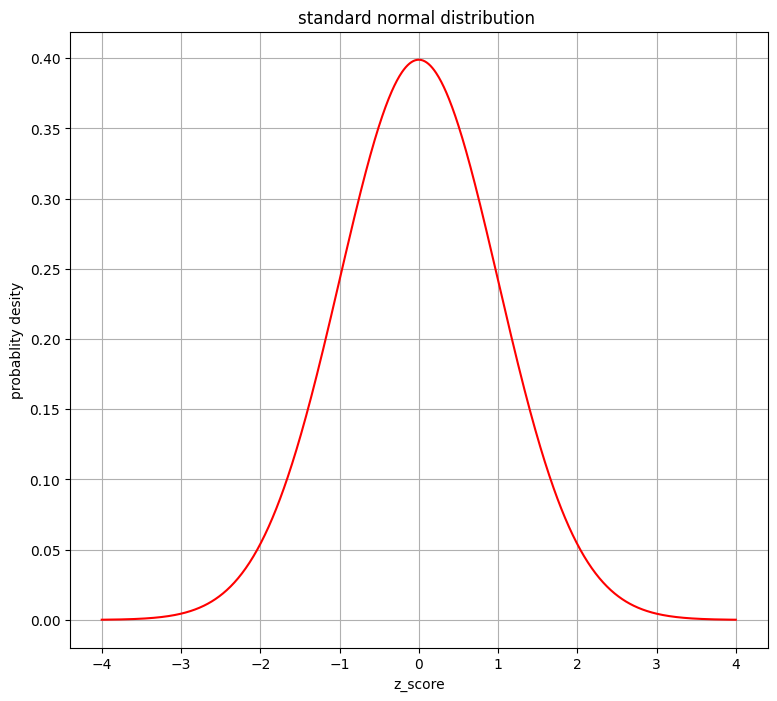

In [41]:
x = np.linspace(-4,4,1000)
y = norm.pdf(x)
plt.figure(figsize= (9,8))
plt.plot(x,y,color = "red")
plt.title("standard normal distribution ")
plt.xlabel("z_score")
plt.ylabel("probablity desity")
plt.grid(True)
plt.show()

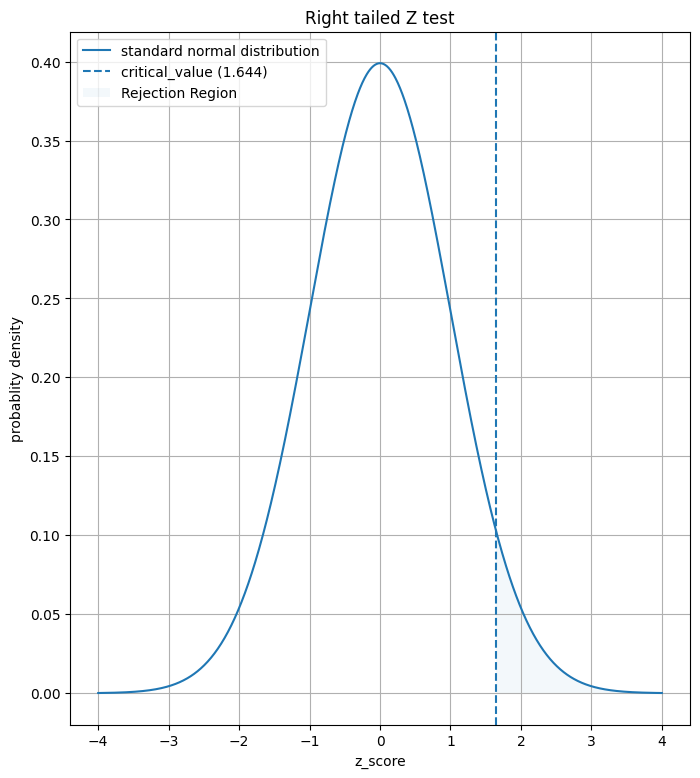

In [53]:
plt.figure(figsize=(8,9))
plt.plot(x,y,label= "standard normal distribution")
plt.axvline(critical_value,linestyle = "--",label = "critical_value (1.644)")
plt.fill_between(
    x,
    y,
    where=(x >= critical_value),
    alpha=0.05,
    label="Rejection Region"
)
plt.title("Right tailed Z test")
plt.xlabel("z_score")
plt.ylabel("probablity density")
plt.legend()
plt.grid(True)
plt.show()